# 01 · First look at dataset v1

**Milestone 1.** Before training anything, check that the data are what we think they are. A
model trained on a broken case, a swapped sign or a misaligned row learns the error faithfully,
and nothing downstream will flag it.

This notebook:

1. **Data card:** what is in the file, where it came from, and the input ranges.
2. **Inputs:** how the 1,056 soil profiles fill the input space.
3. **Physics checks:** symmetry, the static limit and the sign of Im K, and the ref33x31
   centroid transfer.
4. **Curves:** what the impedance functions look like, and which inputs move them.
5. **The f0 check:** do the curves respond where the soil column's own frequency says they
   should?
6. **What the models will see:** the target array and its scales.
7. **Findings and decisions** carried into Milestone 2.

Run it with the `ml` kernel (top right in VS Code), then *Run All*. Every result is deterministic,
so your numbers will match the findings at the end.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from surrogate import style
from surrogate.data import DEFAULT_NPZ, DOF, load_dataset, make_targets

style.apply()
# This notebook looks at the data as delivered, so it keeps all 133 frequencies (fmin=None,
# fmax=None). Modelling uses load_dataset() with its defaults: 0.45-14.95 Hz (see ml/README.md).
ds = load_dataset(fmin=None, fmax=None)                       # every K at its raft's centroid
raw = load_dataset(to_centroid=False, fmin=None, fmax=None)   # as computed, at NRADIER: only for section 3c
f = ds.freqs
print(len(ds), "cases")
print(*ds.notes, sep="\n")

3232 cases
loaded dataset_v1.npz
ref33x31: K moved from NRADIER to the centroid (r = 1.171, 0.807 m)


## 1 · Data card

`ds.frame()` is a pandas **DataFrame**: a table with named columns, one row per case, where
each column keeps its own type (text for labels, floats for inputs). `pd.crosstab` counts rows
by two labels at once.

In [2]:
manifest = json.loads(DEFAULT_NPZ.with_name("dataset_v1_manifest.json").read_text())
df = ds.frame()
print(f"K {ds.K.shape} {ds.K.dtype} | {len(f)} frequencies, {f[0]:g}-{f[-1]:g} Hz, step {f[1] - f[0]:g} Hz")
print("generated from git commits:", ", ".join(manifest["git_commits"]), "| skipped cases:", len(manifest["skipped"]))
print("non-finite values in K:", int((~np.isfinite(ds.K)).sum()))
pd.crosstab(df.mesh_id, df.split, margins=True, margins_name="total")

K (3232, 133, 6, 6) complex64 | 133 frequencies, 0.2-33.2 Hz, step 0.25 Hz
generated from git commits: 0e6d403, 5ef40ba | skipped cases: 0
non-finite values in K: 0


split,test,train,total
mesh_id,,,
m30x15,32,512,544
m45x15,32,512,544
m60x15,32,512,544
m80x20,32,512,544
ref33x31,32,1024,1056
total,160,3072,3232


In [3]:
footprints = df.groupby("mesh_id")[["L_x", "L_y"]].first()
footprints["L/B"] = footprints.max(axis=1) / footprints.min(axis=1)
footprints["area [m²]"] = footprints.L_x * footprints.L_y
footprints

,L_x,L_y,L/B,area [m²]
mesh_id,,,,
m30x15,30.0,15.0,2.000000,450.0
m45x15,45.0,15.0,3.000000,675.0
m60x15,60.0,15.0,4.000000,900.0
m80x20,80.0,20.0,4.000000,1600.0
ref33x31,33.0,31.0,1.064516,1023.0


In [4]:
# Input ranges over all cases. The seven thicknesses and g are sampled; H_bedrock, vs_avg and
# f0 are derived from them (see collect_dataset.py).
df.describe().T[["min", "50%", "max"]].round(3)

,min,50%,max
t_L1,4.000,7.010,9.990
t_L2,3.000,5.020,6.990
t_L3,10.010,13.900,17.990
t_L4,2.000,3.470,5.000
t_L5,12.010,17.060,21.980
t_L6,10.010,13.970,17.990
t_L7,30.010,37.970,45.990
g_factor,0.667,0.997,1.499
L_x,30.000,45.000,80.000
L_y,15.000,15.000,31.000


## 2 · How the soils fill the input space

Every footprint was run with **the same soils** (a *crossed* design), so one mesh shows them
all: 1,024 training soils from a scrambled Halton sequence and 32 test soils drawn at random.

What to look for:

- **Thicknesses and g are flat.** Halton fills each range evenly; g is flat on a log axis
  because it was sampled log-uniformly (×1.5 and ÷1.5 equally likely).
- **H_bedrock is bell-shaped.** It is the sum of seven independent thicknesses, so extreme
  depths need all seven to be extreme at once: rare. This is the central limit theorem at work.
  The model will see few very shallow or very deep sites.
- **Space-filling against random** (last panel): the Halton points avoid each other and leave
  no large gaps; the random test points can clump.

The test soils are shown as ticks along the bottom of each histogram (32 points are too few
for a histogram of their own).

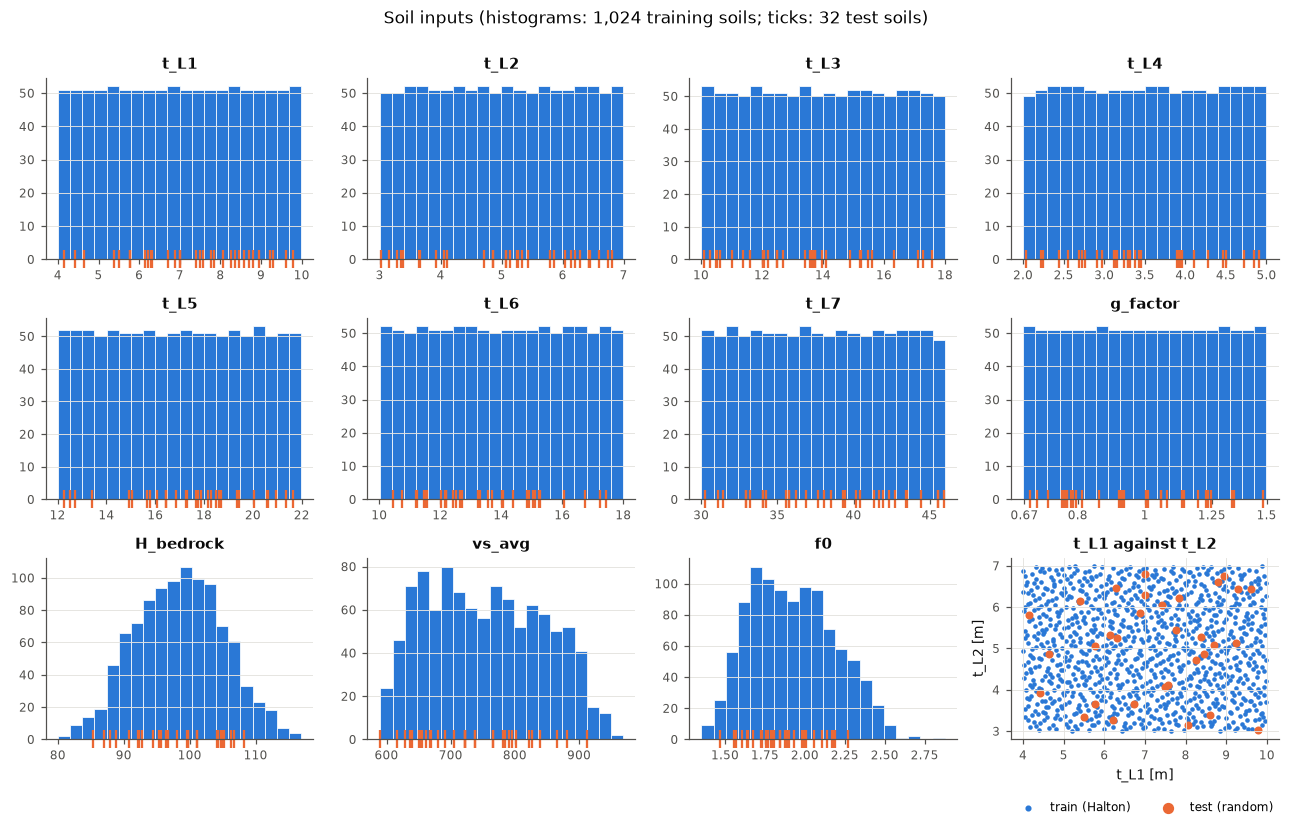

In [5]:
soils = ds.select(mesh="ref33x31").frame()
train, test = soils[soils.split == "train"], soils[soils.split == "test"]
cols = list(ds.x_names[:8]) + list(ds.d_names)

fig, axes = plt.subplots(3, 4, figsize=(12, 7.5))
for ax, c in zip(axes.flat, cols):
    log = c == "g_factor"
    bins = np.geomspace(train[c].min(), train[c].max(), 21) if log else 20
    ax.hist(train[c], bins=bins, color=style.SERIES[0], edgecolor="white", linewidth=0.5)
    ax.plot(test[c], np.zeros(len(test)), "|", color=style.SERIES[1], ms=12, mew=1.5, clip_on=False)
    if log:
        ax.set_xscale("log")
        ax.set_xticks([0.67, 0.8, 1, 1.25, 1.5], ["0.67", "0.8", "1", "1.25", "1.5"])
        ax.minorticks_off()
    ax.set_title(c)
    ax.grid(axis="x", visible=False)

ax = axes.flat[-1]
ax.scatter(train.t_L1, train.t_L2, s=4, color=style.SERIES[0], label="train (Halton)")
ax.scatter(test.t_L1, test.t_L2, s=18, color=style.SERIES[1], label="test (random)")
ax.set(title="t_L1 against t_L2", xlabel="t_L1 [m]", ylabel="t_L2 [m]")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, markerscale=1.5)
fig.suptitle("Soil inputs (histograms: 1,024 training soils; ticks: 32 test soils)", y=1.0)
fig.tight_layout()

## 3 · Physics checks

### 3a · Symmetry, and a glitch at the lowest frequency

Reciprocity makes the true impedance matrix symmetric, K_ij = K_ji. The boundary-element
solution is not exactly symmetric, so the leftover asymmetry measures numerical error. It is
scaled here by √(|K_ii| |K_jj|), the natural size of a coupling between DOFs i and j.

`rel_asym` works on whole arrays: `K[..., i, j]` means "all leading axes (case, frequency), then
row i, column j". The result has one value per case and frequency.

In [6]:
def rel_asym(K, i, j):
    # |K_ij - K_ji| / sqrt(|K_ii| |K_jj|), for every case and frequency
    return np.abs(K[..., i, j] - K[..., j, i]) / np.sqrt(np.abs(K[..., i, i]) * np.abs(K[..., j, j]))

pairs = [(i, j) for i in range(6) for j in range(i + 1, 6)]
rows = {}
for m in style.MESH_ORDER:
    K = ds.select(mesh=m).K
    A = np.stack([rel_asym(K, i, j) for i, j in pairs], axis=-1)    # (case, freq, 15 pairs)
    rows[m] = {"median, all": np.median(A),
               "worst at 0.2 Hz": A[:, 0].max(),
               "worst from 0.45 Hz": A[:, 1:].max()}
(pd.DataFrame(rows).T * 100).round(4).rename(columns=lambda c: c + " [%]")

,"median, all [%]",worst at 0.2 Hz [%],worst from 0.45 Hz [%]
m30x15,0.0000,1.9802,0.0113
m45x15,0.0000,1.2248,0.0059
m60x15,0.0000,0.8981,0.0056
m80x20,0.0000,0.2546,0.0016
ref33x31,0.0006,0.8478,0.0460


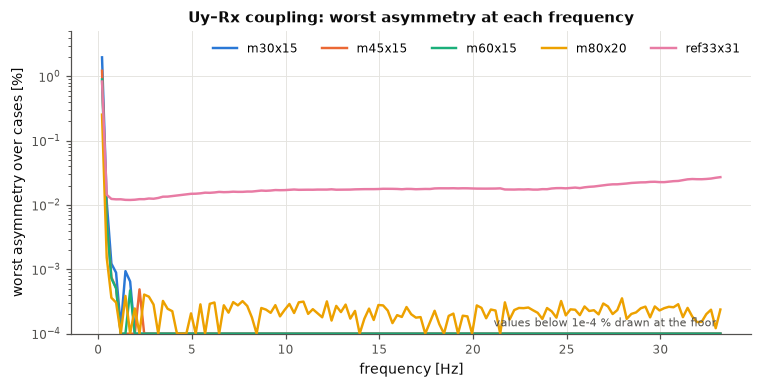

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for m in style.MESH_ORDER:
    a = rel_asym(ds.select(mesh=m).K, 1, 3) * 100                  # Uy-Rx, the worst pair
    ax.plot(f, np.maximum(a.max(axis=0), 1e-4), color=style.MESH_COLORS[m], lw=1.6, label=m)
ax.set_yscale("log")
ax.set_ylim(1e-4, 5)
ax.set(xlabel="frequency [Hz]", ylabel="worst asymmetry over cases [%]",
       title="Uy–Rx coupling: worst asymmetry at each frequency")
ax.legend(ncol=5, loc="upper right")
ax.text(33, 1.3e-4, "values below 1e-4 % drawn at the floor", ha="right", color=style.INK2, fontsize=7)
fig.tight_layout()

Away from the first frequency the matrices are symmetric to a few hundredths of a percent.
Almost all of the asymmetry sits at **0.2 Hz**, in a minority of cases. Is the 0.2 Hz point
itself less reliable? Test it directly: predict each curve's value at 0.2 Hz by extending the
next three points (a quadratic through 0.45, 0.7 and 0.95 Hz), and measure the miss in percent
of the curve's max |K|, the scale of the error metric. Do the same one step later, at 0.45 Hz,
as the reference for a smooth curve.

In [8]:
from surrogate.data import TERMS
K8 = ds.K[:, :, [t[1] for t in TERMS], [t[2] for t in TERMS]]       # (case, freq, 8 terms)
curve_scale = np.abs(K8).max(axis=1)                                  # max |K| per case and term

def miss(k):
    # value at frequency index k against a quadratic through the next three points, % of max |K|
    predicted = 3 * K8[:, k + 1] - 3 * K8[:, k + 2] + K8[:, k + 3]
    return 100 * np.abs(K8[:, k] - predicted) / curve_scale

m0, m1 = miss(0), miss(1)
names = [t[0] for t in TERMS]
pd.DataFrame({"0.2 Hz: median": np.median(m0, axis=0), "0.2 Hz: 99th pct": np.percentile(m0, 99, axis=0),
              "0.2 Hz: worst": m0.max(axis=0), "0.45 Hz: median": np.median(m1, axis=0),
              "0.45 Hz: 99th pct": np.percentile(m1, 99, axis=0), "0.45 Hz: worst": m1.max(axis=0)},
             index=names).round(3)

,0.2 Hz: median,0.2 Hz: 99th pct,0.2 Hz: worst,0.45 Hz: median,0.45 Hz: 99th pct,0.45 Hz: worst
Ux,0.145,0.672,0.917,0.238,0.883,1.267
Uy,0.153,0.657,0.968,0.253,0.882,1.235
Uz,0.076,0.738,1.208,0.050,0.501,0.916
Rx,0.039,2.814,7.568,0.012,0.110,0.122
Ry,0.018,1.968,5.822,0.011,0.035,0.065
Rz,0.014,0.831,1.966,0.010,0.063,0.116
Ux-Ry,0.225,2.025,7.394,0.362,1.218,1.956
Uy-Rx,0.290,2.845,10.928,0.424,1.399,2.498


In [9]:
glitch = (m0 > 1).any(axis=1)                       # a miss above 1 % in any of the 8 terms
print(f"cases with a 0.2 Hz miss above 1 %: {glitch.sum()} of {len(ds)}")
print(pd.Series(ds.mesh_id[glitch]).value_counts().reindex(style.MESH_ORDER).to_string())
print(f"g_factor of those cases: median {np.median(ds.X[glitch, 7]):.2f} (all cases: {np.median(ds.X[:, 7]):.2f})")

cases with a 0.2 Hz miss above 1 %: 215 of 3232
m30x15      78
m45x15      51
m60x15      28
m80x20       1
ref33x31    57
g_factor of those cases: median 1.28 (all cases: 1.00)


For translations, both points miss by a similar small amount: that is just curvature the
quadratic does not follow. For **rocking and the couplings**, the 0.2 Hz point misses by up to
6–11 %, against at most ~0.1 % (rocking) and ~2.5 % (couplings) at 0.45 Hz. The glitches come
mostly in stiff soils (high g) and on the smaller footprints, where the wavelength at 0.2 Hz is
thousands of times the raft size: very low dimensionless frequency, which boundary-element
methods are known to find numerically difficult.

So the first frequency is the least reliable point in the dataset. Section 4 normalises by the
value at 0.45 Hz for that reason, and the findings propose leaving 0.2 Hz out of the targets.

### 3b · The static limit and the sign of Im K

At the lowest reliable frequency (0.45 Hz, see 3a) the impedance should be close to the static
stiffness:

- **Re K_ii positive**, with the static values spanning the range of soils and footprints;
- **Im K_ii small**: 0.45 Hz is below the layer's cut-off frequency, so almost no energy radiates
  away. For rocking, Im/Re should then equal the material (hysteretic) damping alone; the
  translations already carry a little more.

The *sign* of Im K depends on the time convention (e^{+iωt} gives Im K > 0 for damping,
e^{−iωt} gives Im K < 0). Any convention is fine for the ML as long as it is the same in every
case. Re K can also cross zero at high frequency; that matters for the error metric (a
relative error divided by a value near zero explodes) and rules out taking log(Re K).

In [10]:
d = np.diagonal(ds.K, axis1=2, axis2=3)          # (case, freq, 6): the six diagonal terms
d0 = d[:, 1]                                     # at 0.45 Hz
table = pd.DataFrame({
    "static Re K min": d0.real.min(axis=0),
    "static Re K max": d0.real.max(axis=0),
    "max / min": d0.real.max(axis=0) / d0.real.min(axis=0),
    "Im/Re at 0.45 Hz (median)": np.median(d0.imag / d0.real, axis=0),
    "share Im K < 0 [%]": (d.imag < 0).mean(axis=(0, 1)) * 100,
    "cases with Re K <= 0": (d.real <= 0).any(axis=1).sum(axis=0),
}, index=DOF)
table.style.format({"static Re K min": "{:.3g}", "static Re K max": "{:.3g}", "max / min": "{:.1f}",
                    "Im/Re at 0.45 Hz (median)": "{:.4f}", "share Im K < 0 [%]": "{:.1f}"})

,static Re K min,static Re K max,max / min,Im/Re at 0.45 Hz (median),share Im K < 0 [%],cases with Re K <= 0
Ux,8.21e+04,3.72e+05,4.5,-0.0185,100.0,152
Uy,8.63e+04,4.1e+05,4.8,-0.0189,100.0,77
Uz,8.77e+04,4.4e+05,5.0,-0.0174,100.0,0
Rx,6.68e+06,8.32e+07,12.5,-0.0101,100.0,0
Ry,1.79e+07,4.83e+08,26.9,-0.0101,100.0,0
Rz,1.69e+07,4.46e+08,26.3,-0.0100,100.0,0


In [11]:
# Where does Re K go negative? (frequency range and footprints)
for k in (0, 1):
    case_idx, freq_idx = np.nonzero(d.real[:, :, k] <= 0)
    if case_idx.size:
        print(f"{DOF[k]}: Re K <= 0 between {f[freq_idx].min():g} and {f[freq_idx].max():g} Hz, "
              f"in {np.unique(case_idx).size} cases of {sorted(set(ds.mesh_id[case_idx]))}")

Ux: Re K <= 0 between 26.2 and 33.2 Hz, in 152 cases of [np.str_('m60x15'), np.str_('m80x20'), np.str_('ref33x31')]
Uy: Re K <= 0 between 28.2 and 33.2 Hz, in 77 cases of [np.str_('m80x20'), np.str_('ref33x31')]


### 3c · The ref33x31 centroid transfer

ref33x31's reference node NRADIER is 1.17 m / 0.81 m off the centroid, which creates couplings
that a centred rigid raft does not have. `load_dataset()` removes them with K_C = Tᵀ K_N T
(see `surrogate/data.py`). Here is the effect, as the worst coupling over all cases and
frequencies; on the four centred meshes these couplings are zero by symmetry.

In [12]:
def coupling(K, i, j):
    return (np.abs(K[..., i, j]) / np.sqrt(np.abs(K[..., i, i]) * np.abs(K[..., j, j]))).max()

before, after = raw.select(mesh="ref33x31").K, ds.select(mesh="ref33x31").K
centred = ds.select(mesh=["m30x15", "m45x15", "m60x15", "m80x20"]).K
pd.DataFrame({f"{DOF[i]}-{DOF[j]}": {"at NRADIER [%]": 100 * coupling(before, i, j),
                                     "at centroid [%]": 100 * coupling(after, i, j),
                                     "centred meshes [%]": 100 * coupling(centred, i, j)}
              for i, j in [(2, 4), (1, 5), (2, 3), (0, 5), (3, 4), (0, 4), (1, 3)]}).T.round(4)

,at NRADIER [%],at centroid [%],centred meshes [%]
Uz-Ry,15.3323,0.005000,0.000000
Uy-Rz,10.5848,0.003400,0.000000
Uz-Rx,10.9533,0.525800,0.000000
Ux-Rz,6.9162,0.337300,0.000000
Rx-Ry,1.6684,0.008800,0.000000
Ux-Ry,27.4984,27.518299,27.320601
Uy-Rx,27.4032,27.412001,29.120300


The first four couplings exist only because of the offset and drop by 20× to 3,000×. Uz–Rx and
Ux–Rz keep about 0.4 %: the data place this triangle mesh's stiffness centre about 4 cm from
the geometric centroid in y (worked out on 4 October; it is below the mesh's own numerical
noise and changes the 8 target terms by ~1e-5). The last two rows are the couplings the
surrogate learns: they are real physics and the transfer leaves them unchanged.

## 4 · What the curves look like

Each panel shows one term for the ref33x31 training soils, divided by its own value at 0.45 Hz
(the lowest reliable point) so that curves of different stiffness share one scale. Colour is f0 = vs_avg / (4 H), the
fundamental frequency of the soil column: light is low f0 (a deep or soft column), dark is high f0.
Only every fourth case is drawn, to keep the lines readable.

Im K is plotted as −Im K so that it rises with frequency (the dataset's time convention makes
it negative, section 3b).

Text(0.45, 0.98, 'ref33x31, 256 of the 1,024 training soils, coloured by f0')

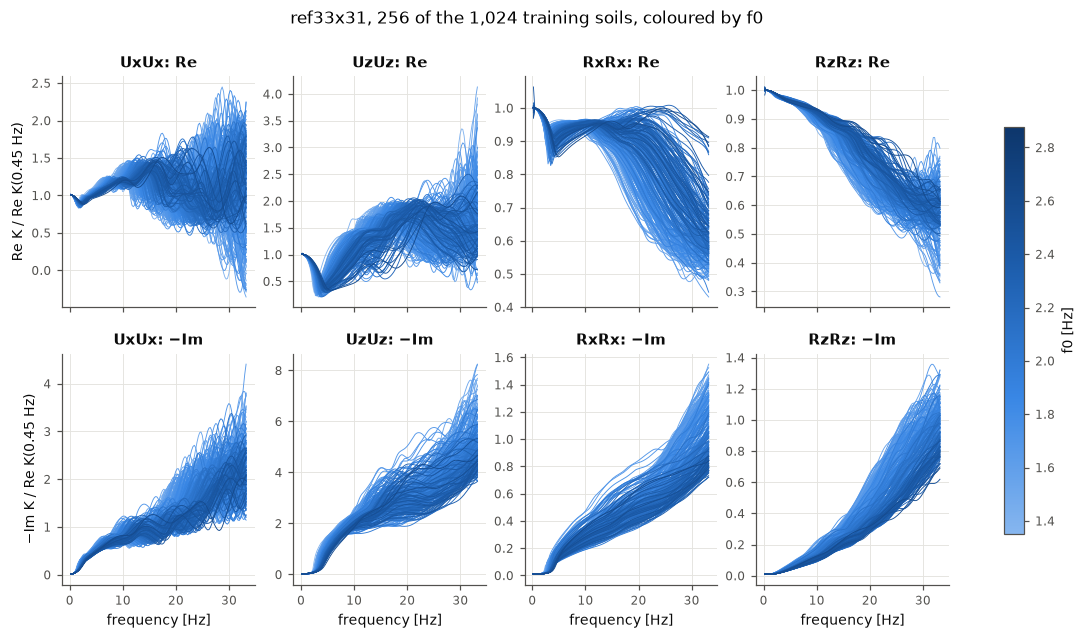

In [13]:
ref = ds.select(mesh="ref33x31", split="train")
f0 = ref.D[:, 2]
norm = plt.Normalize(f0.min(), f0.max())

fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
for col, k in enumerate([0, 2, 3, 5]):                      # Ux, Uz, Rx, Rz
    Kk = ref.K[:, :, k, k]
    s = Kk[:, 1].real[:, None]                              # value at 0.45 Hz, one per case
    for row, (y, label) in enumerate([(Kk.real / s, "Re K / Re K(0.45 Hz)"),
                                      (-Kk.imag / s, "−Im K / Re K(0.45 Hz)")]):
        ax = axes[row, col]
        for n in np.argsort(f0)[::4]:
            ax.plot(f, y[n], color=style.SEQ(norm(f0[n])), lw=0.6)
        ax.set_title(f"{DOF[k]}{DOF[k]}: {'Re' if row == 0 else '−Im'}")
        if col == 0:
            ax.set_ylabel(label)
for ax in axes[1]:
    ax.set_xlabel("frequency [Hz]")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=style.SEQ), ax=axes, label="f0 [Hz]", shrink=0.8)
fig.suptitle("ref33x31, 256 of the 1,024 training soils, coloured by f0", x=0.45)

Things to notice:

- **A dip at low frequency** in Re Ux and Re Uz, and the start of the steep rise in −Im K at the
  same place. Below the soil column's resonance, waves cannot travel away through the layers
  over the stiffer bedrock, so there is almost no radiation damping; above it, radiation
  switches on. Section 5 checks where this happens.
- **The colour sorts the curves.** Light (low-f0) curves dip earlier and spread differently
  from dark ones, so f0 carries much of the information about the curve's shape.
- **Ux becomes wavy above ~15 Hz**, with Re K reaching zero in some cases (section 3b). Wavy,
  case-specific detail is the hardest thing for a surrogate to learn.
- **Rocking (Rx) and torsion (Rz)** are smoother, and fall steadily with frequency.

### 4b · The same soil on every footprint

Because the design is crossed, test case 0001 has the same soil on all five footprints. Here
are the 8 terms the surrogate learns, as |K| on a log scale (the footprints differ by orders of
magnitude in rocking).

soil of test0001: {'t_L1': 4.65, 't_L2': 4.86, 't_L3': 10.11, 't_L4': 2.97, 't_L5': 16.06, 't_L6': 17.23, 't_L7': 32.94, 'g_factor': 0.77}


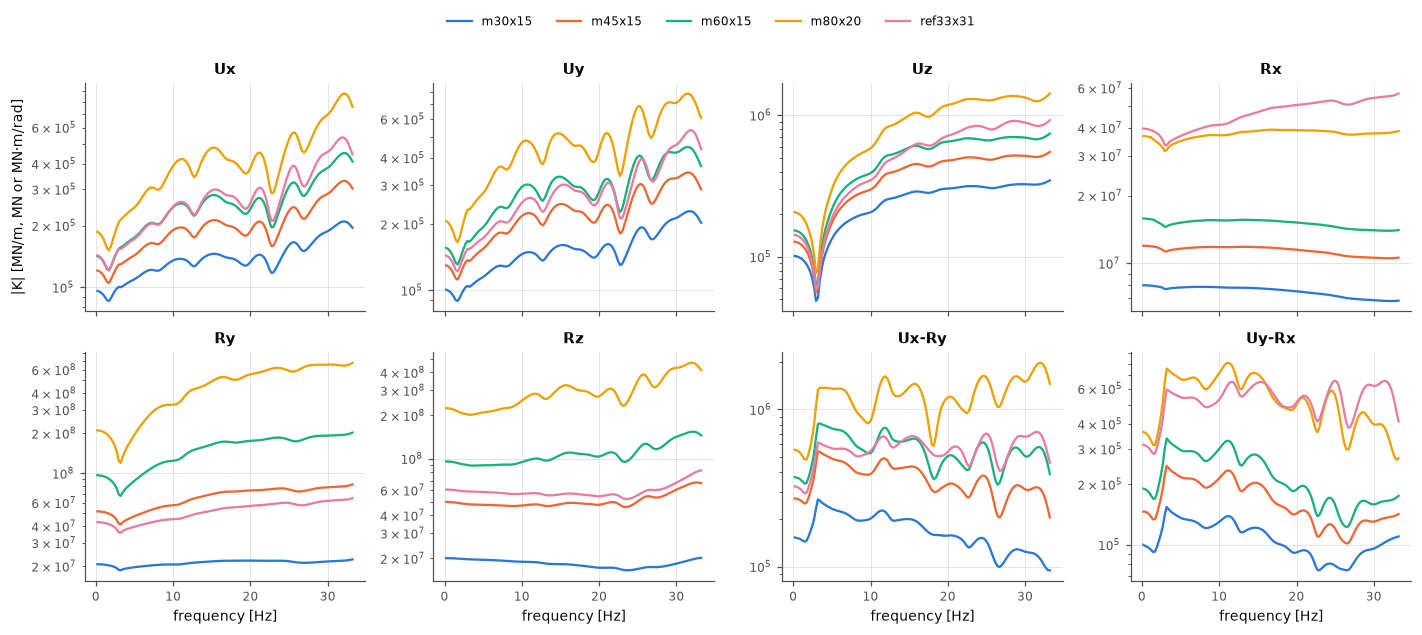

In [14]:
terms = [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (5, 5), (0, 4), (1, 3)]
names = ["Ux", "Uy", "Uz", "Rx", "Ry", "Rz", "Ux-Ry", "Uy-Rx"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharex=True)
for m in style.MESH_ORDER:
    one = ds.select(mesh=m, split="test").take([0])          # test0001 of this footprint
    for ax, (i, j), name in zip(axes.flat, terms, names):
        ax.plot(f, np.abs(one.K[0, :, i, j]), color=style.MESH_COLORS[m], lw=1.5, label=m)
        ax.set_title(name)
        ax.set_yscale("log")
for ax in axes[1]:
    ax.set_xlabel("frequency [Hz]")
axes[0, 0].set_ylabel("|K| [MN/m, MN or MN·m/rad]")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.03))
print("soil of test0001:", dict(zip(ds.x_names[:8], np.round(ds.select(split="test").X[0, :8], 2).tolist())))
fig.tight_layout(rect=(0, 0, 1, 0.96))

## 5 · Do the curves respond at the soil column's frequency?

f0 = vs_avg / (4 H) is a derived feature, computed from the inputs without running anything.
If it is physically meaningful, the dip seen in section 4 should sit at a fixed multiple of f0.
For every case, find the frequency of the lowest Re K between 0.5 and 6 Hz and plot it against
f0.

`np.argmin(..., axis=1)` returns, for each row (case), the position of its minimum; indexing the
frequency band with those positions turns them into frequencies.

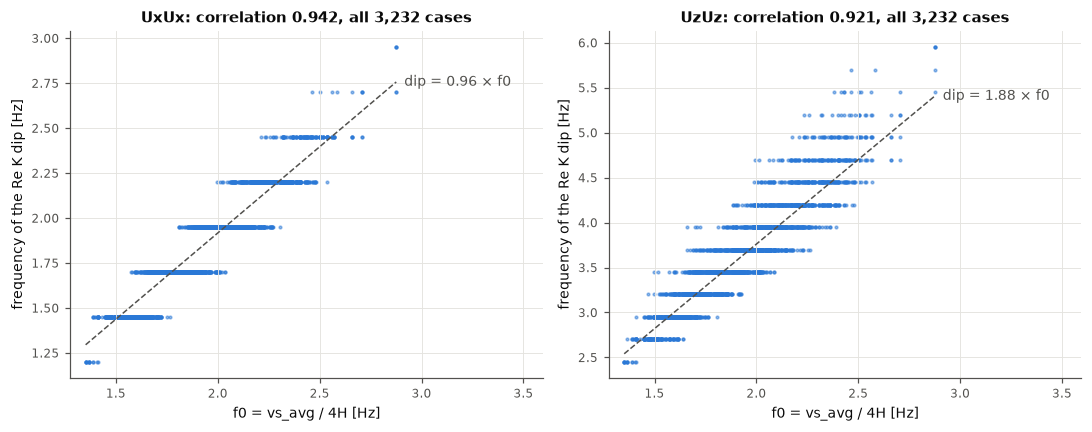

In [15]:
band = (f >= 0.5) & (f <= 6)
f0_all = ds.D[:, 2]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, k in zip(axes, (0, 2)):
    dip = f[band][np.argmin(ds.K[:, band, k, k].real, axis=1)]
    ratio = np.median(dip / f0_all)
    r = np.corrcoef(f0_all, dip)[0, 1]
    ax.scatter(f0_all, dip, s=3, color=style.SERIES[0], alpha=0.5)
    x = np.array([f0_all.min(), f0_all.max()])
    ax.plot(x, ratio * x, color=style.INK2, lw=1, ls="--")
    ax.text(x[1], ratio * x[1], f"  dip = {ratio:.2f} × f0", va="center", color=style.INK2)
    ax.set(xlabel="f0 = vs_avg / 4H [Hz]", ylabel="frequency of the Re K dip [Hz]",
           title=f"{DOF[k]}{DOF[k]}: correlation {r:.3f}, all 3,232 cases")
    ax.set_xlim(right=x[1] * 1.25)
fig.tight_layout()

The horizontal dip sits at about f0 and the vertical one at about 1.9 f0. The vertical ratio is
what Lysmer's analog wave velocity predicts for compression-dominated motion,
V_La = 3.4 Vs / (π(1 − ν)) ≈ 1.7–2.0 Vs for the site's ν = 0.34–0.45.

The horizontal stripes are the 0.25 Hz frequency step: a dip can only be found at a grid point,
which alone keeps the correlation below 1. The rest of the scatter comes from the layering:
vs_avg is a single average for seven layers.

This matters for the ML. The curve's main feature moves with f0, and a feature that moves is
hard to compress into a few fixed shapes (PCA, Milestone 2). Plotting against f / f0 would
line the dips up; that is the "dimensionless frequency" idea to try in Milestone 3.

## 6 · What the models will see

`make_targets` turns the 8 terms into one row of real numbers per case: 8 × 2 × 133 = 2,128
here, and 2,112 once 0.2 Hz is dropped for modelling. The scales of the
terms differ enormously, which decides how the targets must be scaled before training.

In [16]:
Y, spec = make_targets(ds.K)
print("Y:", Y.shape, Y.dtype, f"| {Y.nbytes / 1e6:.0f} MB")
scale = {t: np.abs(Y[:, spec.columns(t, "re")]).max(axis=1) for t in spec.terms}
pd.DataFrame({"median max|Re K|": {t: np.median(v) for t, v in scale.items()},
              "smallest": {t: v.min() for t, v in scale.items()},
              "largest": {t: v.max() for t, v in scale.items()}}).style.format("{:.3g}")

Y: (3232, 2128) float64 | 55 MB


,median max|Re K|,smallest,largest
Ux,2.88e+05,9.88e+04,6.62e+05
Uy,3.35e+05,1.14e+05,9.47e+05
Uz,4.15e+05,1.56e+05,1.09e+06
Rx,2.98e+07,6.68e+06,8.58e+07
Ry,7.21e+07,1.79e+07,6.27e+08
Rz,8.31e+07,1.69e+07,5.19e+08
Ux-Ry,7.2e+05,1.75e+05,3.43e+06
Uy-Rx,4.61e+05,1.02e+05,1.33e+06


Rocking terms are about a thousand times larger than the translations. A model that minimises
squared error on these raw numbers would spend all its effort on Rx and Ry and ignore the
rest, so each term must be scaled to a comparable size first (Milestone 2).

## 7 · Findings and decisions

**Data card (dataset v1).** 3,232 cases (3,072 training, 160 hold-out), five footprints, 133
frequencies 0.2–33.2 Hz, from commits `5ef40ba` and `0e6d403`; no case skipped; SHA-256 of the
npz `9718d80b…fe20`. The soils are shared by all footprints (crossed design): 1,024 Halton
training soils and 32 random test soils.

**Checks passed.**

- No non-finite values; Re K_ii > 0 at the static end for every case.
- **Symmetry:** from 0.45 Hz upwards the matrices are symmetric to within 0.002–0.011 % on the
  structured meshes and 0.046 % on ref33x31 (worst over all pairs, cases and frequencies).
- **Im K_ii is negative** for every case and frequency: one consistent time convention
  (e^{−iωt}). For rocking at 0.45 Hz, Im/Re = −0.0101, the material damping alone: the 0.01
  acts as a loss factor, G(1 + 0.01i), rather than as a damping ratio (which would give 0.02).
  An observation for the engineering side; the ML learns whatever the data contain.
- **The ref33x31 centroid transfer** removes the offset couplings (Uz–Ry 15 % → 0.005 %) and
  leaves the learned couplings untouched.
- **The curves respond where the physics says:** horizontal dip at 0.96 f0, vertical at 1.88 f0
  (correlation 0.94 and 0.92, limited partly by the 0.25 Hz step).

**One weak point: the 0.2 Hz point.** It holds almost all of the asymmetry (up to 2 %), and in
215 of 3,232 cases it departs from the smooth curve by more than 1 % of max |K|, up to 6–11 %
for rocking and the couplings. These cases are mostly stiff soils on the smaller footprints.

**Carried into Milestone 2.**

1. **Decided (4 October): 0.2 Hz is left out of the targets** (132 frequencies, 0.45–33.2 Hz).
   0.45 Hz is still effectively static for every term (section 4), so nothing of engineering
   interest is lost, and the models stop spending effort on a glitch. The same low-frequency
   problem is known from other project cases. `load_dataset()` now drops it by default
   (`FMIN = 0.45`).
2. **Scale each term** before training (rocking ≈ 1,000 × translation).
3. **The error metric divides by max |K| per term**, not by K(f): Re Kxx and Re Kyy cross zero
   at 26–33 Hz on the larger footprints, where a pointwise relative error would explode.
4. **Symmetrising K** hardly matters once 0.2 Hz is gone (asymmetry ≤ 0.05 %); it still decides
   which of the paired couplings is learned, so keep K as computed and learn K_ij with i < j.
5. **The curves' main feature moves with f0.** Expect PCA to need more components than a
   fixed-shape response would, and keep f / f0 in mind for Milestone 3.
6. **H_bedrock is bell-shaped:** errors at very shallow or very deep bedrock deserve a separate
   look, since the training data are thin there.